# Decode the Bioreactor: mass balance, operator clues and sampling times (final)

**STEM4Health Hackathon, Project 1, Team 04.** For 12 test runs only the day-0 measurements are given. This notebook predicts VCD, TCD, substrate and byproduct at the 13 later samples of each run, writes `outputs/submission.csv` and can send it to the leaderboard.

**The idea.** The measurements of a test run are hidden, but its feed log and volume are not. The operators chose those feeds *after looking at the measurements*, so the log still carries their trace. Three first-principles facts turn that trace back into predictions:

1. **Substrate obeys a mass balance.** Tomorrow's reading = today's reading, diluted, plus what the feeds brought in, minus consumption. Fitted per day it explains 57 to 94 % of the run-to-run variation of the next reading (at least 79 % from day 3 on).
2. **The substrate bolus follows fixed thresholds.** After the samples of days 7, 8, 9, 11 and 12: no bolus above about 1.95, a small bolus between 0.97 and 1.95, a large one below 0.97. Feed B was also raised when substrate ran low on days 2 to 6.
3. **Unrecorded volume is base.** Volume that no recorded feed explains in the first days is base added against lactic acid, so it tracks the byproduct.

**One model per predicted value**

| Predicted value | Model | Held-out error | Leaderboard score of this column |
|---|---|---|---|
| VCD | one run-level factor; a Gaussian process and a ridge regression on the day-0 state, averaged; counts moved to a common sampling time | 6.28 % | not scored yet (6.907 without the sampling-time step) |
| TCD | the same, fitted separately; kept at or above VCD | 6.21 % | not scored yet (6.709 without the sampling-time step) |
| Substrate | hidden-state model: mass balance for the moves, the operators' actions as clues | 5.97 % | 6.633 |
| Byproduct | one run-level factor; ridge regression on the day-0 state and the unexplained volume of the first days | 8.51 % | 6.969 |
| **Score** | mean of the four | **6.75 %** | 6.804 with the previous VCD and TCD columns |

- **Held-out error**: each of the 49 training runs is hidden once and predicted from the other 48 (section 4).
- **Leaderboard score of this column**: substrate and byproduct are unchanged from our entry of 22 November (score 6.804), so those two columns keep their scores. VCD and TCD are new in this version and have not been submitted.
- **What changed against the 6.804 entry**: one step in the VCD/TCD model (section 3.1). The samples of a "day" are taken at slightly different hours in each run, and in the first days the cells double in about a day. Every count is therefore moved to the usual sampling time of its day before fitting, and every prediction is moved back to the run's own sampling times. Nothing was chosen or tuned on leaderboard scores.

**Why the simpler byproduct model.** A richer byproduct model (two factors, Feed C shots, late Feed B changes, a correction for the sampling interval) was better in the held-out test (7.49 % against 8.51 %) but worse on the 12 leaderboard runs (7.974 against 6.969). This notebook follows the leaderboard for that one choice. Twelve runs are a small sample, so this is the least certain choice in the notebook.

**How to run**
1. Install the packages in `requirements.txt` (the Renku session of the hackathon already has them).
2. Run all cells (about one minute). The two CSV files are found automatically under `input-data` (next to or above the repository). If they are not, set `DATA_PATH` and `TEMPLATE_PATH` in the first code cell.
3. `outputs/submission.csv` is written. Nothing is sent while `SUBMIT = False`. To submit, set `SUBMIT = True` in the first code cell and run the last cell again; it sends the file as `Team 04`.

The same model without Jupyter: `python src/bioreactor_model.py` (see the repository README).


In [19]:
# ---- settings -------------------------------------------------------------
TEAM_NAME = "Team 04"     # exactly as the organisers wrote it
TEAM_TOKEN = ""           # leave empty unless the organisers gave your team a token
SUBMIT = False           # False: dry run. True: the last cell sends outputs/submission.csv to the leaderboard.
RUN_CV = True             # leave-one-run-out validation, about 30 seconds
DATA_PATH = None          # e.g. "input-data/<folder>/bioreaction_remaining.csv"; None = search automatically
TEMPLATE_PATH = None      # e.g. "input-data/<folder>/bioreaction_template.csv"; None = search automatically
OUT_PATH = "../outputs/submission.csv"

In [5]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel
from sklearn.linear_model import RidgeCV

warnings.filterwarnings("ignore")
TARGETS = ["vcd", "tcd", "substrate", "byproduct"]
NAMES = {"vcd": "VCD", "tcd": "TCD", "substrate": "Substrate", "byproduct": "Byproduct"}
DAYS = list(range(1, 14))                              # the 13 samples to predict
LEADERBOARD = "https://leaderboard-project1-runai-innovation-thibaut.inference.compute.datascience.ch/api/v1"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#898781"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
                     "axes.axisbelow": True, "axes.edgecolor": GREY, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
                     "text.color": INK, "axes.facecolor": SURFACE, "figure.facecolor": SURFACE, "figure.dpi": 110, "lines.linewidth": 2})


def find_file(pattern):
    for root in ("input-data", "../input-data", "../../input-data", ".", ".."):        # the usual places in a Renku session
        if Path(root).exists():
            hits = sorted(Path(root).rglob(pattern))
            if hits:
                return hits[0]
    raise FileNotFoundError(f"Could not find {pattern}. Set DATA_PATH / TEMPLATE_PATH in the first code cell.")


DATA_PATH = Path(DATA_PATH) if DATA_PATH else find_file("*bioreaction_remaining*.csv")
TEMPLATE_PATH = Path(TEMPLATE_PATH) if TEMPLATE_PATH else find_file("*bioreaction_template*.csv")
print("data:    ", DATA_PATH)
print("template:", TEMPLATE_PATH)

data:     ../../input-data/Project 1 - DTB/bioreaction_remaining.csv
template: ../../input-data/Project 1 - DTB/bioreaction_template.csv


## 1. Data

`bioreaction_remaining.csv` is an event log. A **sample row** carries the volume and the four measurements. A **feed row** carries the amount of one feed added at that moment. The log is reshaped into tables with one row per run:

- `Y`: the four measurements at the 14 samples (hidden after day 0 for test runs)
- `T`, `V`: the time and the reactor volume of the 14 samples (given for test runs too)
- `FB`, `FS`: Feed B and substrate feed added between one sample and the next
- `gap`: volume change between two samples that the four recorded feeds do not explain

From these come the inputs `X`, all of which exist for test runs:

| Input | Meaning | Used by |
|---|---|---|
| `lvcd0`, `viab0`, `sub0`, `lbyp0`, `V0` | day-0 state: VCD, viability, substrate, byproduct, volume | all |
| `fb_mid` | Feed B per litre and per day on days 4 to 8, relative to the other runs | VCD, TCD |
| `inn1` … `inn12` | change of the Feed B rate from one day to the next | substrate (days 2 to 6) |
| `fsX7`, `fsX8`, `fsX9`, `fsXany` | a substrate bolus was given after day 7, 8 or 9 | VCD, TCD |
| `gap0` … `gap4` | unexplained volume in each of the first five intervals | byproduct |

The substrate model reads the feeds, volumes and times directly.

In [6]:
def load(path):
    df = pd.read_csv(path)
    df["to_predict"] = df["to_predict"].astype(str).str.strip().str.lower().eq("true")
    samples = df[df["volume"].notna()].copy()                    # sample rows carry a volume, feed rows do not
    samples["k"] = samples.groupby("batch_id").cumcount()        # sample index 0..13
    feeds = df[df["volume"].isna()].copy()
    runs = list(dict.fromkeys(df["batch_id"]))
    test = [r for r in runs if samples.loc[samples["batch_id"] == r, "to_predict"].any()]
    train = [r for r in runs if r not in test]
    assert (samples.groupby("batch_id").size() == 14).all(), "every run should have 14 samples"
    wide = lambda col: samples.pivot(index="batch_id", columns="k", values=col).loc[runs]
    Y, T, V = {c: wide(c) for c in TARGETS}, wide("elapsed_time"), wide("volume")
    F = {name: pd.DataFrame(0.0, index=runs, columns=range(13)) for name in ("feed_b", "feed_substrate", "feed_c", "feed_d")}
    for run, g in feeds.groupby("batch_id"):
        k = np.clip(np.searchsorted(T.loc[run].values, g["elapsed_time"].values, side="left") - 1, 0, 12)   # interval k = from sample k to sample k+1
        for name in F:
            F[name].loc[run] = np.bincount(k, weights=g[name].fillna(0.0).values, minlength=13)
    dV = V.diff(axis=1).iloc[:, 1:]; dV.columns = range(13)
    gap = dV - (F["feed_b"] + F["feed_substrate"] + F["feed_c"] + F["feed_d"])
    return dict(samples=samples, runs=runs, train=train, test=test, Y=Y, T=T, V=V, FB=F["feed_b"], FS=F["feed_substrate"], gap=gap)


def bolus_category(D):
    """0 = no substrate bolus after the sample, 1 = small (0.4 % of the volume), 2 = large (0.6 %)"""
    frac = D["FS"] / D["V"].iloc[:, :13].values
    return (frac > 0).astype(int) + (frac > 0.005).astype(int)


def features(D):
    Y, T, V, FB, gap = D["Y"], D["T"], D["V"], D["FB"], D["gap"]
    X = pd.DataFrame(index=D["runs"])
    X["lvcd0"], X["viab0"], X["sub0"] = np.log(Y["vcd"][0]), Y["vcd"][0] / Y["tcd"][0], Y["substrate"][0]
    X["lbyp0"], X["V0"] = np.log(Y["byproduct"][0]), V[0]
    rate = pd.DataFrame({k: np.log(FB[k] / V[k] / (T[k] - T[k - 1])) for k in range(1, 13)})     # Feed B per litre and per day (log)
    dev = rate - rate.mean()
    X["fb_mid"] = dev[[4, 5, 6, 7, 8]].mean(axis=1)
    X["inn1"] = dev[1]
    for k in range(2, 13):                                                                       # day-to-day change of the Feed B rate
        a, b = dev[k], dev[k - 1]
        X[f"inn{k}"] = a - (a * b).sum() / (b * b).sum() * b
    cat = bolus_category(D)
    for k in (7, 8, 9):
        X[f"fsX{k}"] = (cat[k] > 0).astype(float)
    X["fsXany"] = X[["fsX7", "fsX8", "fsX9"]].max(axis=1)
    for k in range(5):
        X[f"gap{k}"] = gap[k]
    assert not X.isna().any().any(), "an input is missing"
    return X


DAY0 = ["lvcd0", "viab0", "sub0", "lbyp0", "V0"]
D = load(DATA_PATH)
X = features(D)
train, test_ids = D["train"], D["test"]
print(f"{len(train)} training runs, {len(test_ids)} test runs, {X.shape[1]} inputs")
print("test runs:", ", ".join(test_ids))
X.loc[test_ids, DAY0 + ["fb_mid", "fsXany"]].round(3)

49 training runs, 12 test runs, 27 inputs
test runs: Batch5, Batch6, Batch12, Batch24, Batch32, Batch35, Batch40, Batch48, Batch54, Batch56, Batch57, Batch60


,lvcd0,viab0,sub0,lbyp0,V0,fb_mid,fsXany
Batch5,0.279,0.985,4.743,-1.197,10.505,0.035,0.0
Batch6,0.006,0.982,4.900,-1.347,10.397,0.011,1.0
Batch12,0.240,0.985,4.751,-1.306,10.488,-0.030,0.0
Batch24,-0.067,0.991,4.741,-1.415,10.426,-0.034,0.0
Batch32,0.310,0.992,4.591,-1.205,10.438,0.030,0.0
Batch35,0.125,0.983,4.681,-1.386,10.311,0.007,1.0
Batch40,0.218,0.984,4.602,-1.196,10.490,0.006,0.0
Batch48,0.096,0.983,4.694,-1.385,10.372,0.060,0.0
Batch54,0.065,0.982,4.163,-1.268,10.469,0.038,1.0
Batch56,0.005,0.990,4.739,-1.343,10.533,-0.026,0.0


## 2. Helpers shared by the models

- **Standardise** the inputs with the training runs' mean and spread. In the straight-line half of the VCD/TCD model, inputs further than 3 standard deviations out are held at 3, so a run far outside the training range cannot swing it.
- **MAPE factor**: MAPE divides the miss by the true value, so predicting double costs 100 % and predicting half costs 50 %. After fitting, each day's predictions are multiplied by the factor between 0.75 and 1.10 that gives the lowest MAPE on the training runs.

In [7]:
def standardise(A, B, clip=None):
    m, s = A.mean(0), A.std(0)
    keep = s > 1e-9                                    # an input that is constant in the training runs is ignored
    s = np.where(keep, s, 1.0)
    A, B = (A - m) / s, (B - m) / s * keep
    return (np.clip(A, -clip, clip), np.clip(B, -clip, clip)) if clip else (A, B)


def mape_factor(y, pred, lo=0.75, hi=1.10):
    f = np.linspace(lo, hi, int(round((hi - lo) / 0.005)) + 1)
    return f[int(np.argmin([np.mean(np.abs(y - c * pred) / y) for c in f]))]

## 3. The three models

### 3.1 VCD and TCD: one factor per run

All runs follow the same recipe, so their curves share one shape, and a run is high or low on all 13 days at once:

`log curve of a run = typical log curve + z_run × shape`

`shape` is the first principal component of the 49 training log-curves and `z_run` is one number per run. Two models predict `z_run`:

- a **Gaussian process** on the five day-0 measurements. It follows the curved effect of the seeding density (flat below a day-0 VCD of 1.0, rising to 1.2, flat above).
- a **ridge regression** on day-0 VCD, day-0 byproduct, day-0 volume, the mid-run Feed B rate and whether a substrate bolus was needed on days 7 to 9. A straight line continues sensibly outside the training range, where a Gaussian process falls back to the average run.

The prediction is the geometric mean of the two. Five test runs start outside the training range in at least one day-0 measurement, which is why the straight-line half is there: when the six most extreme training runs in a direction are held out together, the average of the two models scores about 6.7 % on VCD against 7.2 % for the Gaussian process alone (TCD: 6.6 % against 7.1 %).

**Sampling times (new in this version).** The samples of one "day" are not taken at the same hour in every run: the sampling time varies between runs with a standard deviation of 0.02 to 0.03 days (half an hour to 45 minutes), and single runs are off by two hours. On days 1 to 4 the typical curve grows at a rate of 0.76, 0.70, 0.58 and 0.45 per day (it roughly doubles per day at first), so a sample taken one hour early reads about 3 % lower on day 1. The model removes this before it compares runs:

`log count at the usual time = log count − growth rate of the day × (sampling time − usual sampling time of that day)`

- The growth rate is the slope of the typical log-curve at the usual sampling time. It is read off the curve; no number is fitted or tuned.
- The model is fitted on the counts moved to the usual time, and each prediction is moved back to the run's own sampling times, which are given for test runs.
- After day 6 the curve is nearly flat, so the step changes the predictions by less than 1 % there.

In [8]:
from scipy.interpolate import PchipInterpolator

CELL_LINEAR = ["lvcd0", "lbyp0", "V0", "fb_mid", "fsXany"]


def growth_rate(c, D, train):
    """Slope of the typical log-curve (per day) at the usual sampling time of days 1 to 13, and those usual times."""
    usual = D["T"].loc[train].mean().values                        # usual sampling time of the 14 samples, day 0 included
    typical = np.log(D["Y"][c].loc[train]).mean().values
    return PchipInterpolator(usual, typical).derivative()(usual[1:]), usual[1:]


def cell_model(c, D, X, train, target, time_correction=True):
    A = D["Y"][c].loc[train, DAYS].values
    rate, usual = growth_rate(c, D, train)
    if not time_correction:                                        # the model of our 6.804 entry
        rate = np.zeros(13)
    late_train = D["T"].loc[train, DAYS].values - usual            # days a sample was taken later (+) or earlier (-) than usual
    late_target = D["T"].loc[target, DAYS].values - usual
    L = np.log(A) - rate * late_train                              # every training count moved to the usual sampling time
    typical = L.mean(0)
    U, S, Vt = np.linalg.svd(L - typical, full_matrices=False)
    z, shape = U[:, 0] * S[0], Vt[0]
    members = []
    Fa, Fb = standardise(X.loc[train, DAY0].values, X.loc[target, DAY0].values)
    gp = GaussianProcessRegressor(ConstantKernel(1.0) * RBF(3.0, (0.5, 50)) + WhiteKernel(0.5, (1e-2, 5)), normalize_y=True).fit(Fa, z)
    members.append((gp.predict(Fa), gp.predict(Fb)))
    Fa, Fb = standardise(X.loc[train, CELL_LINEAR].values, X.loc[target, CELL_LINEAR].values, clip=3.0)
    ridge = RidgeCV(alphas=np.logspace(-2, 4, 31)).fit(Fa, z)
    members.append((ridge.predict(Fa), ridge.predict(Fb)))
    log_pred = 0.0
    for z_fit, z_new in members:
        fitted = np.exp(typical + np.outer(z_fit, shape) + rate * late_train)      # back at each run's own sampling times
        pred = np.exp(typical + np.outer(z_new, shape) + rate * late_target)
        log_pred = log_pred + np.log(pred * np.array([mape_factor(A[:, j], fitted[:, j]) for j in range(13)])) / len(members)
    return np.exp(log_pred)

### 3.2 Substrate: a hidden-state model

The substrate reading of a test run is hidden at 13 samples. The model keeps a *belief* about each of them (a probability for every value from 0.04 to 8 on a fine grid) and updates it with two kinds of knowledge.

**Moves: the mass balance.** For each day a regression on the training runs gives

`G[k+1] = a + b × (G[k] × V[k] + 300 × bolus[k]) / V[k+1] + c × (interval length − 1 day) + d × Feed B[k] / V[k+1] + noise`

The fitted numbers have a physical reading: the substrate feed holds about 300 units of substrate per litre, Feed B about 50 on most days, and from day 3 the culture consumes between 3 and 5 units per litre and day on most days. The leave-one-out spread of the noise is 0.05 to 0.17.

**Clues: what the operators did.**
- The bolus given after the samples of days 7, 8, 9, 11 and 12 says on which side of the two thresholds the reading was. Every one of the 245 training decisions follows the rule.
- On days 2 to 6 the Feed B rate was raised when the reading was low. The link is fitted per day and used only where it is clear (t below −2.5).

A forward and a backward pass combine all moves and clues, so a clue on day 12 also sharpens day 11 and day 10. The prediction is the middle of the belief, tilted halfway towards low values because MAPE punishes a prediction that is too high more than one that is too low.

In [9]:
GRID_G = np.arange(0.04, 8.0001, 0.02)     # possible substrate readings
C_BOLUS = 300.0                             # substrate per litre of substrate feed; the fitted value is 300 to 320


def substrate_fit(D, X, train):
    G, V, T, FB, FS = D["Y"]["substrate"], D["V"], D["T"], D["FB"], D["FS"]
    cat = bolus_category(D)
    M = {"move": {}, "clue": {}}
    for k in range(13):                     # mass balance from sample k to sample k+1
        g_after = ((G[k] * V[k] + C_BOLUS * FS[k]) / V[k + 1]).loc[train].values
        cols = [g_after, (T[k + 1] - T[k]).loc[train].values - 1.0]
        if k > 0:
            cols.append((FB[k] / V[k + 1]).loc[train].values)
        A = np.column_stack([np.ones(len(train))] + cols); y = G.loc[train, k + 1].values
        b = np.linalg.lstsq(A, y, rcond=None)[0]; res = y - A @ b
        leverage = np.einsum("ij,jk,ik->i", A, np.linalg.pinv(A.T @ A), A)
        M["move"][k] = (b, float(np.sqrt(np.mean((res / (1 - leverage)) ** 2))))                 # leave-one-out spread
    for k in range(2, 13):                  # Feed B was raised when substrate was low: change of rate ~ a + b * G[k]
        x, y = G.loc[train, k].values, X.loc[train, f"inn{k}"].values
        A = np.column_stack([np.ones(len(train)), x]); b = np.linalg.lstsq(A, y, rcond=None)[0]
        s = (y - A @ b).std(ddof=2)
        if b[1] / (s / np.sqrt(((x - x.mean()) ** 2).sum())) < -2.5:                             # keep a clue only where the link is clear
            M["clue"][k] = (b, float(s))
    low = [(G.loc[r, k], cat.loc[r, k]) for r in train for k in (11, 12)]
    high = [(G.loc[r, k], cat.loc[r, k]) for r in train for k in (7, 8, 9)]
    M["th_low"] = 0.5 * (max(g for g, c in low if c == 2) + min(g for g, c in low if c == 1))      # below: large bolus
    M["th_high"] = 0.5 * (max(g for g, c in high if c >= 1) + min(g for g, c in high if c == 0))   # below: a bolus at all
    return M


def substrate_belief(run, D, X, M, jitter=0.012):
    """Probability of every possible reading at each of the 14 samples of one run (rows = samples, columns = GRID_G)."""
    G, V, T, FB, FS = D["Y"]["substrate"], D["V"], D["T"], D["FB"], D["FS"]
    cat = bolus_category(D); g = GRID_G; n = len(g)

    def clue(k):
        e = np.ones(n)
        if k in (7, 8, 9, 11, 12):
            below_low = norm.cdf((np.log(M["th_low"]) - np.log(g)) / jitter)
            below_high = norm.cdf((np.log(M["th_high"]) - np.log(g)) / jitter)
            e = e * (1 - below_high, below_high - below_low, below_low)[int(cat.loc[run, k])]
        if k in M["clue"]:
            b, s = M["clue"][k]
            e = e * norm.pdf(X.loc[run, f"inn{k}"], b[0] + b[1] * g, s)
        return e + 1e-300

    P = []
    for k in range(13):
        b, s = M["move"][k]
        mu = b[0] + b[1] * (g * V.loc[run, k] + C_BOLUS * FS.loc[run, k]) / V.loc[run, k + 1] + b[2] * (T.loc[run, k + 1] - T.loc[run, k] - 1.0)
        if k > 0:
            mu = mu + b[3] * FB.loc[run, k] / V.loc[run, k + 1]
        K = norm.pdf(g[None, :], mu[:, None], s); K = K / (K.sum(1, keepdims=True) + 1e-300)
        P.append((1 - 1e-6) * K + 1e-6 / n)             # tiny floor: no reading is ever ruled out completely
    fwd = np.zeros((14, n)); fwd[0, np.argmin(np.abs(g - G.loc[run, 0]))] = 1.0      # day 0 is known
    for k in range(13):
        v = (fwd[k] @ P[k]) * clue(k + 1); fwd[k + 1] = v / v.sum()
    bwd = np.ones((14, n))
    for k in range(12, -1, -1):
        v = P[k] @ (bwd[k + 1] * clue(k + 1)); bwd[k] = v / v.sum()
    belief = fwd * bwd
    return belief / belief.sum(1, keepdims=True)


def belief_quantile(belief, q, tilt=0.0):
    w = belief / GRID_G[None, :] ** tilt
    c = np.cumsum(w, 1) / w.sum(1, keepdims=True)
    return np.array([np.interp(q, c[k], GRID_G) for k in range(belief.shape[0])])


def substrate_model(D, X, train, target, tilt=0.5):
    """tilt 0 = median of the belief, tilt 1 = the exact MAPE-optimal point if the belief were perfectly calibrated"""
    M = substrate_fit(D, X, train)
    return np.array([belief_quantile(substrate_belief(r, D, X, M), 0.5, tilt)[1:] for r in target])

### 3.3 Byproduct: one factor per run

The byproduct has no threshold rule to exploit. Like the cell counts it is predicted with one run-level factor, `log curve of a run = typical log curve + z_run × shape`, and a ridge regression predicts `z_run` from

- the **day-0 state**, and
- the **unexplained volume of the first five intervals**. Around day 2 the volume rises by about 40 mL more than the recorded feeds explain. That is base added against lactic acid, and runs that needed more of it stay higher in byproduct to the end.

This is the byproduct model of our first notebook, unchanged, so this column is the one that scored 6.969 on the leaderboard.

In [10]:
BYPRODUCT_INPUTS = DAY0 + [f"gap{k}" for k in range(5)]


def byproduct_model(D, X, train, target):
    A = D["Y"]["byproduct"].loc[train, DAYS].values
    L = np.log(A); typical = L.mean(0)
    U, S, Vt = np.linalg.svd(L - typical, full_matrices=False)
    z, shape = U[:, 0] * S[0], Vt[0]
    Fa, Fb = standardise(X.loc[train, BYPRODUCT_INPUTS].values, X.loc[target, BYPRODUCT_INPUTS].values)
    ridge = RidgeCV(alphas=np.logspace(-1, 4, 26)).fit(Fa, z)
    fitted, pred = np.exp(typical + np.outer(ridge.predict(Fa), shape)), np.exp(typical + np.outer(ridge.predict(Fb), shape))
    return pred * np.array([mape_factor(A[:, j], fitted[:, j]) for j in range(13)])


def predict(D, X, train, target):
    """Fit on the training runs, predict the target runs. Returns {variable: DataFrame(runs x days 1..13)}."""
    out = {"vcd": cell_model("vcd", D, X, train, target), "tcd": cell_model("tcd", D, X, train, target)}
    out["tcd"] = np.maximum(out["tcd"], out["vcd"])              # total cells cannot be fewer than viable cells
    out["substrate"] = substrate_model(D, X, train, target)
    out["byproduct"] = byproduct_model(D, X, train, target)
    return {c: pd.DataFrame(out[c], index=target, columns=DAYS) for c in TARGETS}

## 4. Validation: leave one run out

Each training run is hidden once and predicted from its day-0 values, feed log and volumes alone, exactly like a test run. Everything that learns from data is refitted each time: curve shapes, regressions, mass balances, thresholds and clue links. The baseline predicts the average training curve for every run. The column for our first notebook is copied from its own run of the same test; its byproduct model is the one used here, so that row is the same in both.

In [11]:
FIRST_NOTEBOOK = {"vcd": 6.42, "tcd": 6.31, "substrate": 7.39, "byproduct": 8.51}      # our first notebook in the same leave-one-run-out test
LEADERBOARD_SO_FAR = {                                                                # what the leaderboard returned for our earlier submissions
    "21 Nov, first notebook": {"vcd_mape": 7.151, "tcd_mape": 6.903, "substrate_mape": 7.546, "byproduct_mape": 6.969, "mean_mape": 7.142},
    "22 Nov, richer byproduct model": {"vcd_mape": 6.907, "tcd_mape": 6.709, "substrate_mape": 6.633, "byproduct_mape": 7.974, "mean_mape": 7.056},
    "22 Nov, entry on the board": {"vcd_mape": 6.907, "tcd_mape": 6.709, "substrate_mape": 6.633, "byproduct_mape": 6.969, "mean_mape": 6.804}}


def cross_validate(D, X):
    train = D["train"]
    P = {c: pd.DataFrame(index=train, columns=DAYS, dtype=float) for c in TARGETS}
    for held in train:
        p = predict(D, X, [r for r in train if r != held], [held])
        for c in TARGETS:
            P[c].loc[held] = p[c].loc[held].values
    return P


def error_table(D, P):
    truth = lambda c: D["Y"][c].loc[P[c].index, DAYS].values
    return {c: np.abs(truth(c) - P[c].values) / truth(c) * 100 for c in TARGETS}


if RUN_CV:
    P_cv = cross_validate(D, X)
    P_base = {c: pd.DataFrame([D["Y"][c].loc[[r for r in train if r != held], DAYS].mean().values for held in train], index=train, columns=DAYS) for c in TARGETS}
    E, E_base = error_table(D, P_cv), error_table(D, P_base)
    summary = pd.DataFrame({"baseline: average curve": {NAMES[c]: E_base[c].mean() for c in TARGETS},
                            "first notebook": {NAMES[c]: FIRST_NOTEBOOK[c] for c in TARGETS},
                            "this notebook": {NAMES[c]: E[c].mean() for c in TARGETS}})
    summary.loc["SCORE (mean of the four)"] = summary.mean()
    display(summary.round(2))
    per_run = np.mean([E[c].mean(axis=1) for c in TARGETS], axis=0)
    print(f"uncertainty of the score (standard error over the 49 runs): +/- {per_run.std(ddof=1) / np.sqrt(len(per_run)):.2f}")

,baseline: average curve,first notebook,this notebook
VCD,8.77,6.42,6.28
TCD,8.80,6.31,6.21
Substrate,11.67,7.39,5.97
Byproduct,11.86,8.51,8.51
SCORE (mean of the four),10.27,7.16,6.75


uncertainty of the score (standard error over the 49 runs): +/- 0.25


### Does the sampling-time step help?

The same leave-one-run-out test for the cell model with and without the step. The change is computed run by run, so its standard error says how sure the gain is. Read it plainly: a change smaller than about twice its standard error cannot be told from zero with 49 runs.

In [12]:
if RUN_CV:
    hold = lambda held: [r for r in train if r != held]
    old = {c: np.vstack([cell_model(c, D, X, hold(held), [held], time_correction=False)[0] for held in train]) for c in ("vcd", "tcd")}
    old["tcd"] = np.maximum(old["tcd"], old["vcd"])
    rows = {}
    for c in ("vcd", "tcd"):
        truth = D["Y"][c].loc[train, DAYS].values
        e_old = np.abs(truth - old[c]) / truth * 100
        diff = E[c].mean(axis=1) - e_old.mean(axis=1)
        rows[NAMES[c]] = {"without the step (6.804 entry)": e_old.mean(), "with the step (this notebook)": E[c].mean(), "change": diff.mean(),
                          "standard error of the change": diff.std(ddof=1) / np.sqrt(len(diff)), "runs improved, of 49": int((diff < 0).sum()),
                          "day 1 without": e_old[:, 0].mean(), "day 1 with": E[c][:, 0].mean()}
    display(pd.DataFrame(rows).T.round(3))

,without the step (6.804 entry),with the step (this notebook),change,standard error of the change,"runs improved, of 49",day 1 without,day 1 with
VCD,6.304,6.280,-0.024,0.034,29.0,7.147,6.791
TCD,6.245,6.215,-0.031,0.037,29.0,7.225,6.915


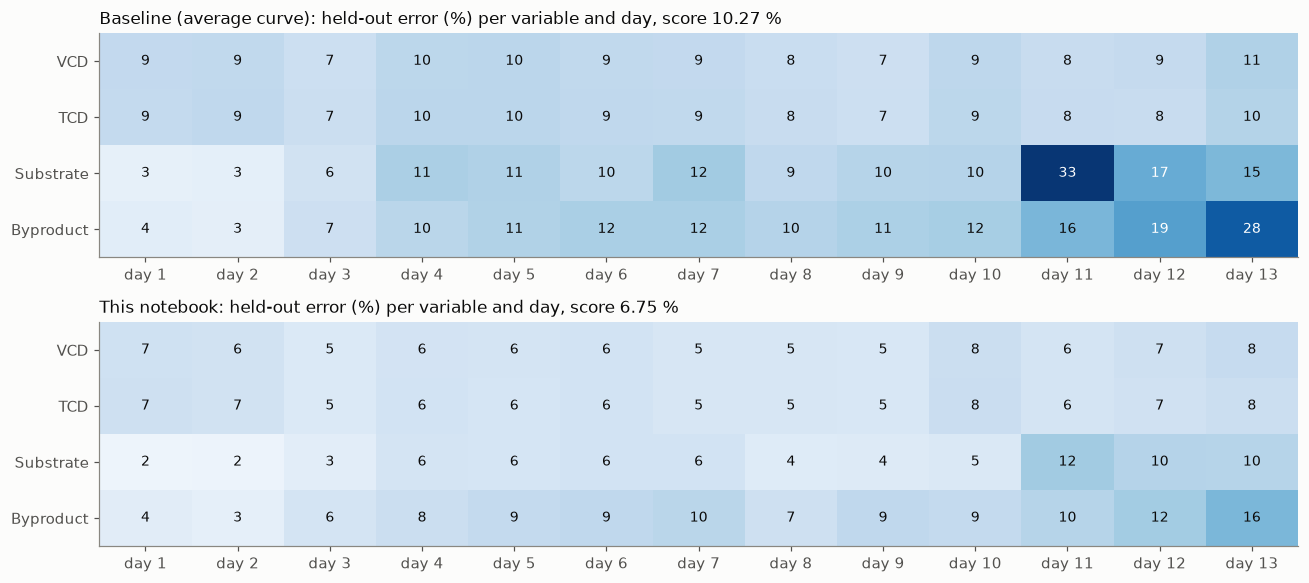

In [13]:
if RUN_CV:
    fig, axs = plt.subplots(2, 1, figsize=(12, 5.4))
    for ax, M_, title in zip(axs, [E_base, E], ["Baseline (average curve)", "This notebook"]):
        M_ = np.array([M_[c].mean(axis=0) for c in TARGETS])
        ax.imshow(M_, cmap="Blues", vmin=0, vmax=34, aspect="auto"); ax.grid(False)
        ax.set_xticks(range(13)); ax.set_xticklabels([f"day {k}" for k in DAYS]); ax.set_yticks(range(4)); ax.set_yticklabels([NAMES[c] for c in TARGETS])
        for i in range(4):
            for j in range(13):
                ax.text(j, i, f"{M_[i, j]:.0f}", ha="center", va="center", fontsize=9, color="white" if M_[i, j] > 17 else INK)
        ax.set_title(f"{title}: held-out error (%) per variable and day, score {M_.mean():.2f} %", loc="left", fontsize=11)
    plt.tight_layout(); plt.show()

## 5. A look inside

**Top row, the three facts on the training runs.** Left: the reading at the five decision days, coloured by the bolus the operators gave; the two dashed lines are the thresholds. Second: the reading the one-day mass balance expects against the reading that was measured, all days pooled. Third: the Feed B rate went up when the reading on days 4 and 5 was low. Right: unexplained volume on days 2 to 4 against the byproduct level on days 8 to 12.

**Bottom row, the substrate belief for four training runs that were hidden from the fit.** The band holds 80 % of the belief, the line is the prediction, the dots are the readings the model did not see.

thresholds found in the training runs: 0.967 and 1.951 | Feed B clue used on days [2, 3, 4, 5, 6]


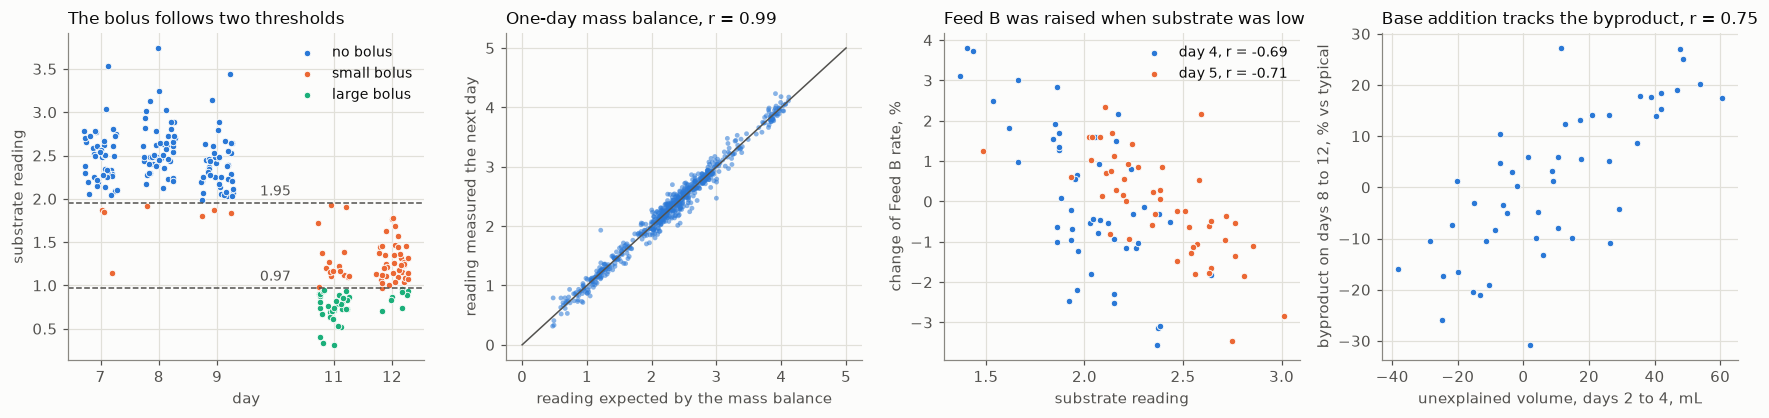

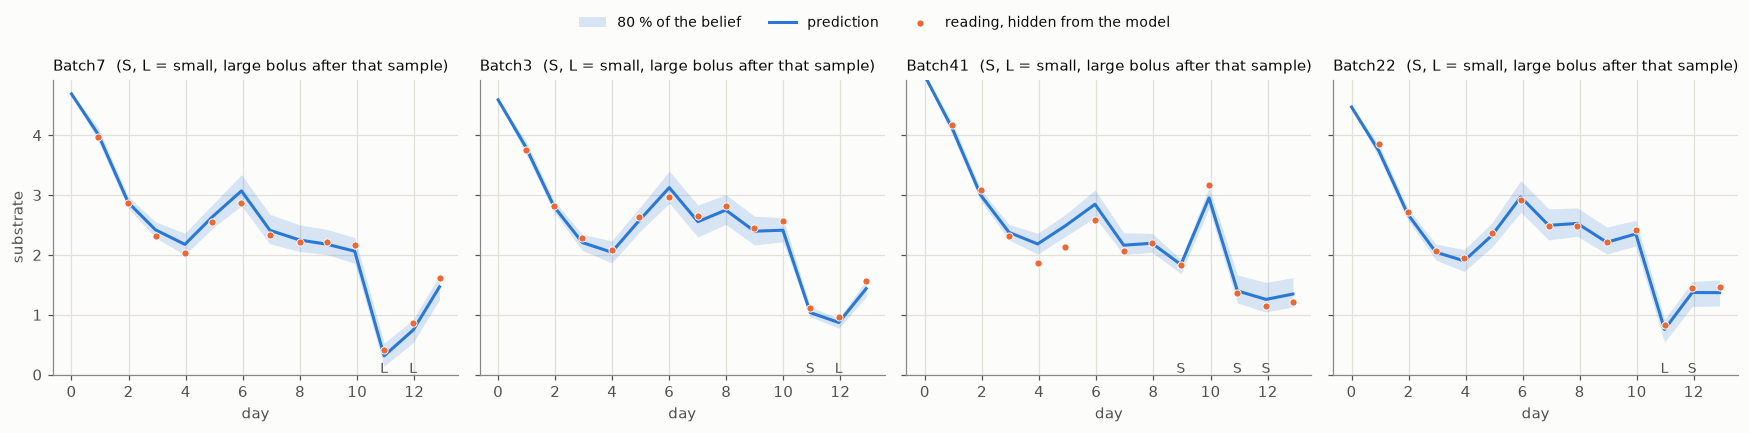

In [14]:
G_ = D["Y"]["substrate"]; cat = bolus_category(D); M_all = substrate_fit(D, X, train)
print(f"thresholds found in the training runs: {M_all['th_low']:.3f} and {M_all['th_high']:.3f} | Feed B clue used on days {sorted(M_all['clue'])}")
fig, axs = plt.subplots(1, 4, figsize=(16, 3.9))

ax = axs[0]; rng = np.random.default_rng(0)
for c, colour, label in ((0, BLUE, "no bolus"), (1, ORANGE, "small bolus"), (2, AQUA, "large bolus")):
    xs, ys = [], []
    for k in (7, 8, 9, 11, 12):
        m = (cat.loc[train, k] == c).values
        xs += list(k + rng.uniform(-0.28, 0.28, int(m.sum()))); ys += list(G_.loc[train, k].values[m])
    ax.scatter(xs, ys, s=18, color=colour, label=label, edgecolor=SURFACE, linewidth=0.6)
for th in (M_all["th_low"], M_all["th_high"]):
    ax.axhline(th, color=MUTED, lw=1, ls="--")
    ax.text(10, th + 0.05, f"{th:.2f}", ha="center", va="bottom", fontsize=9, color=MUTED)
ax.set_xticks([7, 8, 9, 11, 12]); ax.set_xlabel("day"); ax.set_ylabel("substrate reading")
ax.set_title("The bolus follows two thresholds", loc="left", fontsize=11); ax.legend(frameon=False, fontsize=9, loc="upper right")

ax = axs[1]; fit, act = [], []
for k in range(13):
    b, s = M_all["move"][k]
    mu = b[0] + b[1] * ((G_[k] * D["V"][k] + C_BOLUS * D["FS"][k]) / D["V"][k + 1]).loc[train] + b[2] * ((D["T"][k + 1] - D["T"][k]).loc[train] - 1.0)
    if k > 0:
        mu = mu + b[3] * (D["FB"][k] / D["V"][k + 1]).loc[train]
    fit += list(mu.values); act += list(G_.loc[train, k + 1].values)
ax.scatter(fit, act, s=10, color=BLUE, alpha=0.55, edgecolor="none"); ax.plot([0, 5], [0, 5], color=MUTED, lw=1)
ax.set_xlabel("reading expected by the mass balance"); ax.set_ylabel("reading measured the next day")
ax.set_title(f"One-day mass balance, r = {np.corrcoef(fit, act)[0, 1]:.2f}", loc="left", fontsize=11)

ax = axs[2]
for k, colour in ((4, BLUE), (5, ORANGE)):
    ax.scatter(G_.loc[train, k], 100 * X.loc[train, f"inn{k}"], s=18, color=colour, edgecolor=SURFACE, linewidth=0.6,
               label=f"day {k}, r = {np.corrcoef(G_.loc[train, k], X.loc[train, f'inn{k}'])[0, 1]:.2f}")
ax.set_xlabel("substrate reading"); ax.set_ylabel("change of Feed B rate, %")
ax.set_title("Feed B was raised when substrate was low", loc="left", fontsize=11); ax.legend(frameon=False, fontsize=9)

ax = axs[3]
Lb = np.log(D["Y"]["byproduct"].loc[train, [8, 9, 10, 11, 12]]); level = (np.exp((Lb - Lb.mean()).mean(axis=1)) - 1) * 100
gap234 = D["gap"].loc[train, [2, 3, 4]].sum(axis=1)
ax.scatter(1000 * gap234, level, s=18, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
ax.set_xlabel("unexplained volume, days 2 to 4, mL"); ax.set_ylabel("byproduct on days 8 to 12, % vs typical")
ax.set_title(f"Base addition tracks the byproduct, r = {np.corrcoef(gap234, level)[0, 1]:.2f}", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

examples = [r for r in ("Batch7", "Batch3", "Batch41", "Batch22") if r in train] or train[:4]
fig, axs = plt.subplots(1, len(examples), figsize=(16, 3.6), sharey=True)
for ax, run in zip(np.atleast_1d(axs), examples):
    belief = substrate_belief(run, D, X, substrate_fit(D, X, [r for r in train if r != run]))
    t = D["T"].loc[run].values
    ax.fill_between(t, belief_quantile(belief, 0.1), belief_quantile(belief, 0.9), color=BLUE, alpha=0.18, lw=0, label="80 % of the belief")
    ax.plot(t, belief_quantile(belief, 0.5, 0.5), color=BLUE, label="prediction")
    ax.scatter(t[1:], G_.loc[run, DAYS], s=22, color=ORANGE, edgecolor=SURFACE, linewidth=0.6, zorder=3, label="reading, hidden from the model")
    for k in (7, 8, 9, 11, 12):
        if cat.loc[run, k] > 0:
            ax.annotate("L" if cat.loc[run, k] == 2 else "S", (t[k], 0.03), ha="center", fontsize=9, color=MUTED)
    ax.set_title(f"{run}  (S, L = small, large bolus after that sample)", loc="left", fontsize=10); ax.set_xlabel("day"); ax.set_ylim(0, None); ax.set_xticks(range(0, 14, 2))
np.atleast_1d(axs)[0].set_ylabel("substrate")
fig.legend(*np.atleast_1d(axs)[0].get_legend_handles_labels(), frameon=False, fontsize=9, loc="lower center", ncol=3, bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(); plt.show()

## 6. Predict the 12 test runs and write the submission

The models are fitted on all 49 training runs. The predictions are written in the template's row order with its column names and timestamps unchanged.

In [15]:
def make_submission(P, D, template_path):
    template = pd.read_csv(template_path, dtype={"batch_id": str})
    assert list(template.columns) == ["batch_id", "elapsed_time"] + TARGETS, "unexpected template columns"
    assert set(template["batch_id"]) == set(P["vcd"].index), "template runs differ from the test runs"
    rows = []
    for run, t in zip(template["batch_id"], template["elapsed_time"]):
        times = D["T"].loc[run].values; k = int(np.argmin(np.abs(times - t)))
        assert k >= 1 and abs(times[k] - t) < 1e-4, f"timestamp {t} of {run} is not a sample to predict"
        rows.append([P[c].loc[run, k] for c in TARGETS])
    template[TARGETS] = np.array(rows)
    assert template[TARGETS].notna().all().all() and (template[TARGETS] > 0).all().all() and len(template) == 13 * len(P["vcd"])
    return template


P_test = predict(D, X, train, test_ids)
submission = make_submission(P_test, D, TEMPLATE_PATH)
submission.to_csv(OUT_PATH, index=False)
print(f"wrote {OUT_PATH}: {len(submission)} rows, columns {list(submission.columns)}")
print("TCD never below VCD:", bool((submission.tcd >= submission.vcd).all()), "| all values positive:", bool((submission[TARGETS] > 0).all().all()))
submission.head()

wrote submission_sampling_time.csv: 156 rows, columns ['batch_id', 'elapsed_time', 'vcd', 'tcd', 'substrate', 'byproduct']
TCD never below VCD: True | all values positive: True


,batch_id,elapsed_time,vcd,tcd,substrate,byproduct
0,Batch5,0.965972,2.229777,2.255309,3.856180,0.919315
1,Batch5,1.948611,5.187149,5.243187,2.756100,1.857557
2,Batch5,2.940278,9.659732,9.740926,2.015931,2.299870
3,Batch5,3.919444,16.916932,17.107065,1.848029,2.451065
4,Batch5,4.924306,24.932789,25.245680,2.151525,2.367182


,day-0 VCD,"substrate, day 7","substrate, day 8","substrate, day 9","substrate, day 11","substrate, day 12"
Batch5,1.32,1.95 or above,1.95 or above,1.95 or above,below 0.97,0.97 to 1.95
Batch6,1.01,0.97 to 1.95,1.95 or above,1.95 or above,0.97 to 1.95,0.97 to 1.95
Batch12,1.27,1.95 or above,1.95 or above,1.95 or above,below 0.97,0.97 to 1.95
Batch24,0.93,1.95 or above,1.95 or above,1.95 or above,0.97 to 1.95,below 0.97
Batch32,1.36,1.95 or above,1.95 or above,1.95 or above,0.97 to 1.95,0.97 to 1.95
Batch35,1.13,1.95 or above,1.95 or above,0.97 to 1.95,0.97 to 1.95,0.97 to 1.95
Batch40,1.24,1.95 or above,1.95 or above,1.95 or above,below 0.97,0.97 to 1.95
Batch48,1.10,1.95 or above,1.95 or above,1.95 or above,below 0.97,0.97 to 1.95
Batch54,1.07,1.95 or above,1.95 or above,0.97 to 1.95,0.97 to 1.95,0.97 to 1.95
Batch56,1.01,1.95 or above,1.95 or above,1.95 or above,below 0.97,0.97 to 1.95


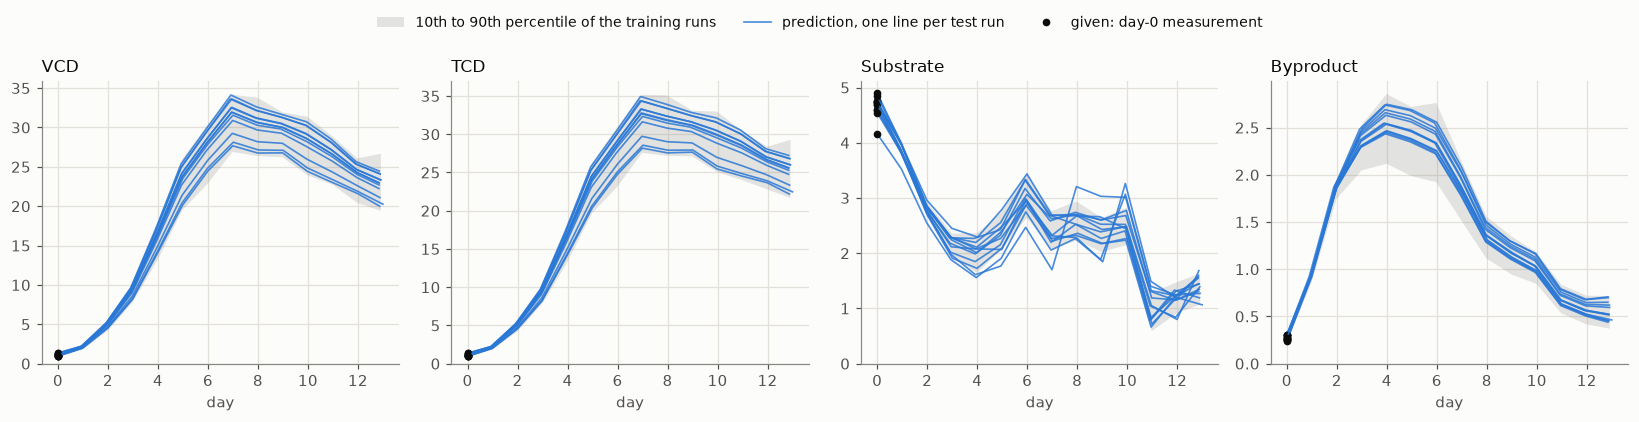

In [16]:
clues = pd.DataFrame(index=test_ids)
clues["day-0 VCD"] = D["Y"]["vcd"].loc[test_ids, 0].round(2)
say = {0: "1.95 or above", 1: "0.97 to 1.95", 2: "below 0.97"}
for k in (7, 8, 9, 11, 12):
    clues[f"substrate, day {k}"] = [say[int(v)] for v in bolus_category(D).loc[test_ids, k]]
display(clues)

fig, axs = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, c in zip(axs, TARGETS):
    band = D["Y"][c].loc[train]
    ax.fill_between(D["T"].loc[train].mean(), band.quantile(0.1), band.quantile(0.9), color=GREY, alpha=0.22, lw=0, label="10th to 90th percentile of the training runs")
    for i, run in enumerate(test_ids):
        ax.plot(D["T"].loc[run], np.r_[D["Y"][c].loc[run, 0], P_test[c].loc[run]], color=BLUE, lw=1.1, alpha=0.85, label="prediction, one line per test run" if i == 0 else None)
        ax.plot(D["T"].loc[run, 0], D["Y"][c].loc[run, 0], "o", ms=4, color=INK, label="given: day-0 measurement" if i == 0 else None)
    ax.set_title(NAMES[c], loc="left", fontsize=11); ax.set_xlabel("day"); ax.set_ylim(0, None); ax.set_xticks(range(0, 14, 2))
plt.tight_layout()
fig.legend(*axs[0].get_legend_handles_labels(), frameon=False, fontsize=9, loc="lower center", ncol=3, bbox_to_anchor=(0.5, 1.0))
plt.show()

### What the sampling-time step does to the 12 test runs

Left: how many hours earlier (−) or later (+) than usual each test run was sampled on days 1 to 5. Right: the resulting change of the VCD prediction against the model of the 6.804 entry, in percent. The later days change by less than 1 %.

In [17]:
rate, usual = growth_rate("vcd", D, train)
late = D["T"].loc[test_ids, DAYS] - usual
hours = (24 * late[[1, 2, 3, 4, 5]]).round(1); hours.columns = [f"hours, day {k}" for k in hours.columns]
without = pd.DataFrame(cell_model("vcd", D, X, train, test_ids, time_correction=False), index=test_ids, columns=DAYS)      # the VCD column of the 6.804 entry
moved = (P_test["vcd"] / without - 1) * 100
change = moved[[1, 2, 3, 4, 5]].round(1); change.columns = [f"VCD %, day {k}" for k in change.columns]
display(pd.concat([hours, change], axis=1))
print("growth rate of the typical VCD curve per day, days 1 to 13:", np.round(rate, 2))
print(f"change of the VCD predictions against the 6.804 entry: {moved.abs().values.mean():.2f} % on average, at most {moved.abs().values.max():.1f} % (days 7 to 13: at most {moved[list(range(7, 14))].abs().values.max():.1f} %)")

,"hours, day 1","hours, day 2","hours, day 3","hours, day 4","hours, day 5","VCD %, day 1","VCD %, day 2","VCD %, day 3","VCD %, day 4","VCD %, day 5"
Batch5,-0.0,-0.5,-0.7,-1.2,-0.8,0.7,-0.5,-1.6,-2.0,-0.1
Batch6,-0.3,0.2,-0.6,-1.1,-0.3,-1.4,0.6,-1.8,-2.2,-0.2
Batch12,-0.3,-0.3,-0.5,-0.6,-0.3,-0.8,-0.4,-1.3,-0.9,0.1
Batch24,0.7,0.5,0.3,1.1,0.8,0.0,0.6,-0.2,1.2,0.1
Batch32,-0.6,-0.6,-1.3,-1.3,-0.8,-0.8,-0.7,-3.0,-1.9,-0.0
Batch35,-0.1,-0.1,-0.2,-1.2,0.6,-0.3,-0.1,-0.9,-2.4,0.7
Batch40,-1.7,-2.1,-1.9,-2.2,-0.7,-4.6,-5.2,-4.5,-3.8,-0.2
Batch48,0.1,1.0,0.9,0.5,0.9,-0.1,2.9,1.7,0.6,0.8
Batch54,0.0,0.4,-0.5,-0.2,0.2,0.3,1.6,-1.4,-0.3,0.5
Batch56,0.0,0.5,0.3,0.3,-0.0,-1.7,1.1,0.2,0.2,-0.1


growth rate of the typical VCD curve per day, days 1 to 13: [ 0.76  0.7   0.58  0.45  0.23  0.15  0.   -0.03 -0.04 -0.06 -0.07 -0.06
 -0.02]
change of the VCD predictions against the 6.804 entry: 0.58 % on average, at most 5.2 % (days 7 to 13: at most 0.6 %)


## 7. Submit to the leaderboard

With `SUBMIT = True` this cell sends `outputs/submission.csv` as `TEAM_NAME` and prints the returned scores next to our earlier submissions. The call is the one from the organisers' `Leaderboard_template` notebook. With `SUBMIT = False` nothing is sent.

In [20]:
def send(submission, team, token=""):
    """Same call as in the organisers' Leaderboard_template notebook."""
    import requests
    r = requests.post(f"{LEADERBOARD}/submit", json={"predictions": submission.to_dict(orient="records")}, auth=(team, token))
    if r.status_code // 100 != 2:
        raise RuntimeError(f"Unexpected error (HTTP {r.status_code}): {r.text}")
    return r.json()["metrics"]


print(f"ready: {len(submission)} rows, {submission.batch_id.nunique()} runs, columns {list(submission.columns)}")
if not SUBMIT:
    print("Dry run only, nothing was sent. Set SUBMIT = True in the first code cell and run this cell again to submit.")
elif TEAM_NAME.strip() in ("", "Team XX", "TEMPLATE"):
    print("Set TEAM_NAME first, so the submission does not go out under a placeholder name.")
else:
    metrics = send(submission, TEAM_NAME, TEAM_TOKEN)
    print("submitted as", TEAM_NAME)
    display(pd.DataFrame({**LEADERBOARD_SO_FAR, "returned now": metrics}).round(3))
    try:
        import requests
        board = pd.json_normalize(requests.get(f"{LEADERBOARD}/leaderboard", timeout=20).json()["entries"])
        display(board.rename(columns=lambda c: c.replace("metrics.", "")).head(10))
    except Exception as e:
        print("could not read the leaderboard:", e)

ready: 156 rows, 12 runs, columns ['batch_id', 'elapsed_time', 'vcd', 'tcd', 'substrate', 'byproduct']
submitted as Team 04


,"21 Nov, first notebook","22 Nov, richer byproduct model","22 Nov, entry on the board",returned now
vcd_mape,7.151,6.907,6.907,6.747
tcd_mape,6.903,6.709,6.709,6.550
substrate_mape,7.546,6.633,6.633,6.633
byproduct_mape,6.969,7.974,6.969,6.969
mean_mape,7.142,7.056,6.804,6.725


,user_name,rank,attempt,timestamp,vcd_mape,tcd_mape,substrate_mape,byproduct_mape,mean_mape
0,Team 04,1,16,2026-11-22T10:56:05.255107,6.747,6.550,6.633,6.969,6.725
1,Team 15,2,8,2026-11-22T08:03:13.449316,6.609,6.463,6.479,7.457,6.752
2,Team 7,3,5,2026-11-21T18:06:56.327299,6.745,6.649,7.234,7.446,7.018
3,Team 23,4,22,2026-11-22T10:34:17.012599,6.743,6.613,6.891,8.097,7.086
4,Team 6,5,9,2026-11-22T10:53:21.823694,6.817,6.588,6.873,8.416,7.174
5,Team 01,6,6,2026-11-22T08:50:00.730814,6.773,6.734,7.389,8.281,7.294
6,Team 10,7,104,2026-11-22T10:05:02.420291,7.164,7.044,8.003,7.644,7.464
7,Team 18,8,15,2026-11-22T10:37:32.192288,7.114,6.968,8.755,9.245,8.021
8,TEMPLATE,9,62,2026-11-21T14:24:40.616352,8.037,7.949,12.023,10.059,9.517


## Limits

- **VCD and TCD of this version have not been scored.** Our entry on the board (6.804) used the same cell model without the sampling-time step. In the held-out test the step changes the error by −0.02 (VCD) and −0.03 (TCD) with a standard error of 0.03 and 0.04, so on 49 runs the gain cannot be told from zero. It is kept because it is a physical effect with no fitted number, and its clearest trace is where it should be: on day 1 the VCD error goes from 7.15 % to 6.79 %. On the 12 test runs it moves the predictions by 0.58 % on average and by at most 5.2 %.
- **Substrate and byproduct are unchanged** from the entry on the board (6.633 and 6.969). They hold as long as the notebook runs on the same two CSV files.
- **The byproduct model was chosen on the 12 leaderboard runs.** In the held-out test on the 49 training runs the richer byproduct model was better (7.49 % against 8.51 %); on the leaderboard it was worse (7.974 against 6.969). The two tests disagree and twelve runs are few, so on new runs either model could be the better one.
- **VCD and TCD are close to their limit.** Even if a run's true overall level were known, the error would still be about 5.4 %, because the cell counts scatter from day to day. The day-0 state explains about half of the run-to-run differences in level; the feed log adds little, and even the run's real substrate and byproduct curves would not add more.
- **Five test runs start outside the training range**: Batch 32 in day-0 VCD, Batch 54 in day-0 substrate, and Batches 5, 40 and 57 in day-0 byproduct. For those the two halves of the VCD/TCD model disagree most (by up to 8 %).
- **The bolus rule is an observation.** It holds in all 245 training decisions. If a test run broke it, its substrate prediction around that day would sit on the wrong side of the threshold.
- **Two training runs have a byproduct reading on day 13 about three times the previous day's.** Such jumps cannot be predicted; if a test run has one, that point costs up to 65 % on its own.
- **Units and chemical identities are not given.** Substrate behaves like glucose and byproduct like lactate, and the models do not depend on that reading.